# Практика 4. Задача о компоте: обучение агента с подкреплением (Q-learning)

**Задание**

- Бабушка разлила по 5 стаканам компот, но сделала это неровно. Надо перелить компот так, чтобы во всех стаканах был одинаковый объём компота.
- Научите агента переливать компот, чтобы он поднимал стаканы для переливания минимальное число раз (можно поднять один стакан и разлить на несколько других — это одно поднятие).
- Нужно вывести кривую обучения (зависимость награды агента от числа эпизодов обучения).

**Идея решения.** Это задача обучения с подкреплением. Пишем *среду* — симуляцию стаканов, в которой можно переливать компот, — и *агента*, который выбирает, откуда и куда лить. Как правильно переливать, агенту не говорим: он получает штраф за каждое поднятие стакана и бонус, когда стаканы выровнены, и за сотни тысяч попыток сам находит стратегию. Алгоритм — табличный Q-learning.

In [1]:
import itertools
import os
import random
import time
from functools import reduce
from math import gcd

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter, MultipleLocator

plt.rcParams["font.family"] = "DejaVu Sans"  # шрифт есть в самом matplotlib, кириллицу поддерживает
os.makedirs("images", exist_ok=True)         # сюда сохраняются графики для README
SEED = 42

## 1. Среда

**Состояние.** Компот меряем в условных порциях. Стаканы одинаковые, поэтому одинаковый объём — это одинаковый уровень (зелёная линия на слайде). Для решения важно не то, сколько компота в стакане, а насколько он выше или ниже этой линии. Поэтому состояние — это отклонения пяти стаканов от среднего, например `(0, -1, 2, 1, -2)`. Их сумма всегда 0, цель — все нули.

Ещё в состояние входит номер стакана, который агент держит в руке (`None` — руки свободны). Без этого агент не отличит «лить дальше из того же стакана» (бесплатно) от «поднять другой стакан» (штраф).

Отклонения ограничены диапазоном от −3 до +3 порций — так число состояний конечно и Q-таблица получается небольшой.

**Действия.** 20 действий «перелить 1 порцию из стакана *i* в стакан *j*» (5 × 4 пары). Если стакан *i* уже в руке, это продолжение того же поднятия. Если нет, агент ставит текущий стакан и поднимает *i* — это новое поднятие. Нельзя лить из стакана на нижней границе и в стакан на верхней.

**Награды**

| Событие | Награда |
|---|---|
| поднятие стакана | −1 |
| во всех стаканах поровну (эпизод заканчивается) | +10 |
| 50 переливаний, а стаканы всё ещё неровные | эпизод обрывается без бонуса |

За решённый эпизод агент получает `10 − число поднятий`, поэтому максимизировать награду — то же самое, что минимизировать число поднятий.

**Эпизод** — одна попытка: бабушка случайно разливает компот (одна из всех возможных неровных расстановок), агент переливает, пока не выровняет стаканы или не кончатся 50 шагов.

In [2]:
def all_level_vectors(n_glasses, max_dev):
    """Все расстановки: отклонения от -max_dev до +max_dev, в сумме 0."""
    values = range(-max_dev, max_dev + 1)
    return [v for v in itertools.product(values, repeat=n_glasses) if sum(v) == 0]


def optimal_lifts(levels):
    """Теоретический минимум поднятий — число стаканов выше среднего (обоснование ниже)."""
    return sum(1 for d in levels if d > 0)


class CompoteEnv:
    def __init__(self, n_glasses=5, max_dev=3, max_steps=50,
                 lift_penalty=1.0, success_reward=10.0, seed=None):
        self.n_glasses = n_glasses
        self.max_dev = max_dev
        self.max_steps = max_steps
        self.lift_penalty = lift_penalty
        self.success_reward = success_reward
        self.rng = random.Random(seed)

        # Действие с номером a — это пара (откуда, куда)
        self.actions = [(i, j) for i in range(n_glasses)
                        for j in range(n_glasses) if i != j]
        self.n_actions = len(self.actions)

        # Все «неровные» расстановки, с которых может начаться эпизод
        self.start_states = [v for v in all_level_vectors(n_glasses, max_dev) if any(v)]

        self.reset()

    def reset(self, levels=None):
        """Начать эпизод. Без аргумента бабушка разливает компот случайно."""
        if levels is None:
            levels = self.rng.choice(self.start_states)
        levels = tuple(levels)
        if (len(levels) != self.n_glasses or sum(levels) != 0
                or max(abs(d) for d in levels) > self.max_dev):
            raise ValueError(f"Недопустимая расстановка: {levels}")
        self.levels = list(levels)
        self.held = None   # какой стакан в руке; None — руки свободны
        self.lifts = 0     # сколько раз поднимали стаканы
        self.steps = 0     # сколько порций перелили
        return self.state()

    def state(self):
        return tuple(self.levels), self.held

    def valid_actions(self):
        """Номера действий, которые можно сделать в текущем состоянии."""
        lo, hi = -self.max_dev, self.max_dev
        return [a for a, (i, j) in enumerate(self.actions)
                if self.levels[i] > lo and self.levels[j] < hi]

    def step(self, action):
        """Сделать действие. Возвращает (состояние, награда, решено, прервано)."""
        i, j = self.actions[action]
        if self.levels[i] <= -self.max_dev or self.levels[j] >= self.max_dev:
            raise ValueError(f"Недопустимое действие: стакан {i + 1} → стакан {j + 1}")

        reward = 0.0
        if self.held != i:            # ставим текущий стакан и поднимаем i
            self.held = i
            self.lifts += 1
            reward -= self.lift_penalty

        self.levels[i] -= 1
        self.levels[j] += 1
        self.steps += 1

        solved = not any(self.levels)
        if solved:
            reward += self.success_reward
        truncated = not solved and self.steps >= self.max_steps
        return self.state(), reward, solved, truncated

Проверим среду вручную на примере со слайда: 1-й стакан на линии, 3-й и 4-й выше, 2-й и 5-й ниже. Поднимем 3-й стакан и дважды перельём из него в 5-й, потом поднимем 4-й и перельём во 2-й.

In [3]:
env = CompoteEnv(seed=SEED)
print("Неровных стартовых расстановок:", len(env.start_states))
print()

state = env.reset((0, -1, 2, 1, -2))
print("старт:", state)
for src, dst in [(3, 5), (3, 5), (4, 2)]:  # стаканы нумеруем с 1, как на слайде
    action = env.actions.index((src - 1, dst - 1))
    state, reward, solved, truncated = env.step(action)
    print(f"стакан {src} → стакан {dst}: {state}, награда {reward:+.0f}, решено: {solved}")
print("поднятий:", env.lifts)

Неровных стартовых расстановок: 1450

старт: ((0, -1, 2, 1, -2), None)
стакан 3 → стакан 5: ((0, -1, 1, 1, -1), 2), награда -1, решено: False
стакан 3 → стакан 5: ((0, -1, 0, 1, 0), 2), награда +0, решено: False
стакан 4 → стакан 2: ((0, 0, 0, 0, 0), 3), награда +9, решено: True
поднятий: 2


Второе переливание из 3-го стакана бесплатное — стакан уже в руке. Последний шаг дал +9: −1 за поднятие 4-го стакана и +10 за ровные стаканы.

### Сколько поднятий — минимум

Минимальное число поднятий равно **числу стаканов, где компота больше среднего**:

- компот уходит из стакана, только если его поднять, поэтому каждый стакан выше среднего придётся поднять хотя бы раз;
- одного раза хватает: излишек из поднятого стакана можно разлить сразу по нескольким стаканам, где компота не хватает.

Агенту это правило **не сообщается** — по нему мы только проверяем, чему он научился.

In [4]:
mins = [optimal_lifts(s) for s in env.start_states]
for k in sorted(set(mins)):
    print(f"минимум {k}: {mins.count(k)} расстановок")

best_lifts = float(np.mean(mins))
best_reward = env.success_reward - env.lift_penalty * best_lifts
print(f"\nВ среднем нужно {best_lifts:.2f} поднятия, значит средняя награда не больше {best_reward:.2f}")

минимум 1: 170 расстановок
минимум 2: 960 расстановок
минимум 3: 320 расстановок

В среднем нужно 2.10 поднятия, значит средняя награда не больше 7.90


## 2. Агент: Q-learning

Агент хранит таблицу $Q(s, a)$ — оценку того, какую суммарную награду он получит до конца эпизода, если в состоянии $s$ сделает действие $a$, а дальше будет действовать наилучшим образом. После каждого шага таблица обновляется:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \left[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \right]$$

- $\alpha$ — скорость обучения, $\gamma$ — насколько важны будущие награды по сравнению с текущей;
- действия выбираются **ε-жадно**: с вероятностью ε — случайное (исследование), иначе — лучшее по таблице (использование найденного);
- $Q_0$ — с какого значения начинаются ещё не испробованные действия. Если взять его больше любой достижимой награды (**оптимистичная инициализация**), незнакомые действия кажутся агенту выгодными, и он сам их перепробует, а не застрянет на первом найденном неплохом варианте.

In [5]:
class QLearningAgent:
    def __init__(self, n_actions, alpha=0.5, gamma=0.99, epsilon=1.0, q_init=0.0, seed=None):
        self.n_actions = n_actions
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.q_init = q_init
        self.rng = random.Random(seed)
        self.Q = {}   # состояние -> массив Q-значений для всех действий

    def q(self, state):
        """Строка Q-таблицы; для нового состояния все действия начинаются с q_init."""
        if state not in self.Q:
            self.Q[state] = np.full(self.n_actions, self.q_init, dtype=float)
        return self.Q[state]

    def act(self, state, valid_actions, greedy=False):
        """ε-жадный выбор действия (greedy=True — всегда лучшее, без исследования)."""
        if not greedy and self.rng.random() < self.epsilon:
            return self.rng.choice(valid_actions)                 # исследуем
        q = self.q(state)
        best = max(q[a] for a in valid_actions)                   # используем
        # если лучших действий несколько, берём любое из них
        return self.rng.choice([a for a in valid_actions if q[a] == best])

    def update(self, state, action, reward, next_state, next_valid, done):
        """Шаг Q-learning: сдвигаем Q(s, a) к r + γ · max Q(s', ·)."""
        target = reward
        if not done:
            q_next = self.q(next_state)
            target += self.gamma * max(q_next[a] for a in next_valid)
        q = self.q(state)
        q[action] += self.alpha * (target - q[action])

## 3. Обучение

| Параметр | Значение | Почему |
|---|---|---|
| эпизодов | 200 000 | хватает с запасом: все расстановки решаются оптимально примерно к 90 000 эпизодов |
| α | 1 | среда детерминированная: одно и то же действие в одном и том же состоянии всегда даёт один и тот же результат, поэтому усреднять нечего — новая оценка сразу заменяет старую |
| γ | 0,99 | бонус в конце эпизода почти так же важен, как ближайшие штрафы; небольшое дисконтирование заодно отучает от лишних переливаний |
| Q₀ | 10 | оптимистичная инициализация: 10 больше любой достижимой награды (максимум 9) |
| ε | 1 → 0,05 | линейно снижается за первые 80 % обучения: сначала агент в основном исследует, в конце — в основном использует найденное |

Каждые 2 000 эпизодов агента проверяем без случайных ходов (ε = 0) на всех расстановках — эти замеры нужны для кривой обучения.

In [6]:
EPISODES = 200_000
ALPHA, GAMMA, Q_INIT = 1.0, 0.99, 10.0
EPS_START, EPS_END = 1.0, 0.05  # доля случайных действий в начале и в конце
EPS_DECAY_SHARE = 0.8           # за какую долю обучения ε падает до EPS_END


def run_episode(env, agent, levels=None, learn=False, greedy=False):
    """Один эпизод. Возвращает (суммарная награда, число поднятий, решено ли)."""
    state = env.reset(levels)
    valid = env.valid_actions()
    total_reward = 0.0
    while True:
        action = agent.act(state, valid, greedy=greedy)
        next_state, reward, solved, truncated = env.step(action)
        next_valid = env.valid_actions()
        if learn:
            agent.update(state, action, reward, next_state, next_valid, solved)
        total_reward += reward
        state, valid = next_state, next_valid
        if solved or truncated:
            return total_reward, env.lifts, solved


def evaluate(env, agent, starts, greedy=True):
    """Прогон без обучения по списку стартов; средние показатели."""
    rewards, lifts, solved, optimal = [], [], [], []
    for levels in starts:
        r, n_lifts, ok = run_episode(env, agent, levels, greedy=greedy)
        rewards.append(r)
        lifts.append(n_lifts)
        solved.append(ok)
        optimal.append(ok and n_lifts == optimal_lifts(levels))
    return {"reward": float(np.mean(rewards)), "lifts": float(np.mean(lifts)),
            "solved": float(np.mean(solved)), "optimal": float(np.mean(optimal))}


def epsilon_at(episode, total):
    """ε линейно падает от EPS_START до EPS_END, дальше не меняется."""
    frac = min(1.0, episode / (EPS_DECAY_SHARE * total))
    return EPS_START + frac * (EPS_END - EPS_START)


def train(episodes, alpha, gamma, q_init, max_dev=3, seed=SEED, eval_points=100, verbose=True):
    """Обучает агента. Возвращает (env, agent, награды по эпизодам, контрольные замеры)."""
    env = CompoteEnv(max_dev=max_dev, seed=seed)
    agent = QLearningAgent(env.n_actions, alpha=alpha, gamma=gamma, q_init=q_init, seed=seed + 1)
    eval_every = max(1, episodes // eval_points)
    log_every = max(1, episodes // 10)

    rewards = np.empty(episodes)
    evals = []  # (эпизод, показатели агента без случайных ходов)
    started = time.time()
    for ep in range(episodes):
        if ep % eval_every == 0:
            evals.append((ep, evaluate(env, agent, env.start_states)))
        agent.epsilon = epsilon_at(ep, episodes)
        rewards[ep], _, _ = run_episode(env, agent, learn=True)

        if verbose and (ep + 1) % log_every == 0:
            last = evals[-1][1]
            recent = rewards[max(0, ep - 999):ep + 1].mean()
            print(f"эпизод {ep + 1:>7,} | ε = {agent.epsilon:.2f} | "
                  f"средняя награда за последние 1000 эп.: {recent:6.2f} | "
                  f"оптимальных решений (ε = 0): {last['optimal']:6.1%} | "
                  f"{time.time() - started:4.0f} с".replace(",", " "))
    evals.append((episodes, evaluate(env, agent, env.start_states)))
    return env, agent, rewards, evals

In [7]:
started = time.time()
env, agent, rewards, evals = train(EPISODES, ALPHA, GAMMA, Q_INIT)
print(f"\nОбучение заняло {time.time() - started:.0f} с, в Q-таблице {len(agent.Q)} состояний")

эпизод  20 000 | ε = 0.88 | средняя награда за последние 1000 эп.: -33.60 | оптимальных решений (ε = 0):  22.6% |   10 с
эпизод  40 000 | ε = 0.76 | средняя награда за последние 1000 эп.: -16.40 | оптимальных решений (ε = 0):  48.7% |   16 с
эпизод  60 000 | ε = 0.64 | средняя награда за последние 1000 эп.:  -3.97 | оптимальных решений (ε = 0):  80.3% |   20 с
эпизод  80 000 | ε = 0.53 | средняя награда за последние 1000 эп.:   1.76 | оптимальных решений (ε = 0):  98.8% |   23 с
эпизод 100 000 | ε = 0.41 | средняя награда за последние 1000 эп.:   4.30 | оптимальных решений (ε = 0): 100.0% |   25 с
эпизод 120 000 | ε = 0.29 | средняя награда за последние 1000 эп.:   5.86 | оптимальных решений (ε = 0): 100.0% |   27 с
эпизод 140 000 | ε = 0.17 | средняя награда за последние 1000 эп.:   6.84 | оптимальных решений (ε = 0): 100.0% |   28 с
эпизод 160 000 | ε = 0.05 | средняя награда за последние 1000 эп.:   7.60 | оптимальных решений (ε = 0): 100.0% |   30 с
эпизод 180 000 | ε = 0.05 | сред

## 4. Кривая обучения

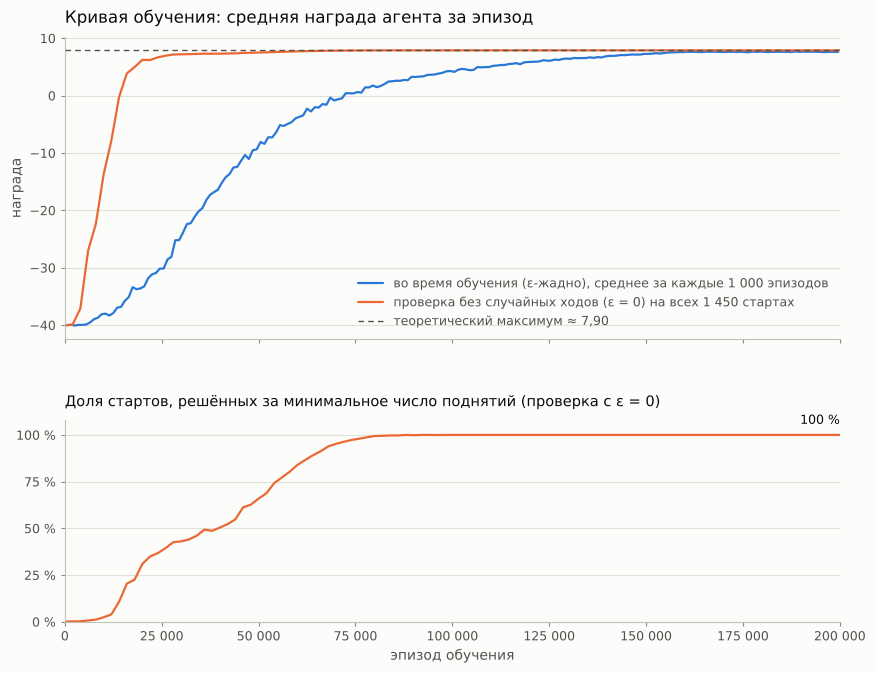

In [8]:
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"


def thousands(x, _pos=None):
    return f"{int(x):,}".replace(",", " ")


def style_axes(ax):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(colors=MUTED, labelcolor=INK_2, labelsize=9, length=3, width=0.8)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def plot_learning_curve(rewards, evals, best_reward, n_starts):
    episodes = len(rewards)
    block = max(1, episodes // 200)
    n_blocks = episodes // block
    block_x = (np.arange(n_blocks) + 0.5) * block
    block_mean = rewards[:n_blocks * block].reshape(n_blocks, block).mean(axis=1)

    eval_x = np.array([ep for ep, _ in evals])
    eval_reward = np.array([m["reward"] for _, m in evals])
    eval_optimal = np.array([m["optimal"] for _, m in evals]) * 100

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 7.6), sharex=True, facecolor=SURFACE,
        gridspec_kw={"height_ratios": [3, 2], "hspace": 0.32})

    # --- 1. Награда за эпизод
    style_axes(ax1)
    ax1.plot(block_x, block_mean, color=BLUE, linewidth=1.6, solid_capstyle="round",
             label=f"во время обучения (ε-жадно), среднее за каждые {thousands(block)} эпизодов")
    ax1.plot(eval_x, eval_reward, color=ORANGE, linewidth=1.6, solid_capstyle="round",
             label=f"проверка без случайных ходов (ε = 0) на всех {thousands(n_starts)} стартах")
    ax1.axhline(best_reward, color=INK_2, linewidth=1.0, linestyle=(0, (4, 3)), zorder=3,
                label=f"теоретический максимум ≈ {best_reward:.2f}".replace(".", ","))
    ax1.set_title("Кривая обучения: средняя награда агента за эпизод",
                  loc="left", color=INK, fontsize=12, pad=10)
    ax1.set_ylabel("награда", color=INK_2, fontsize=10)
    ax1.yaxis.set_major_locator(MultipleLocator(10))
    ax1.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK_2)

    # --- 2. Насколько политика оптимальна
    style_axes(ax2)
    ax2.plot(eval_x, eval_optimal, color=ORANGE, linewidth=1.6, solid_capstyle="round")
    ax2.annotate(f"{eval_optimal[-1]:.0f} %", (eval_x[-1], eval_optimal[-1]),
                 xytext=(0, 8), textcoords="offset points", ha="right", color=INK, fontsize=9)
    ax2.set_title("Доля стартов, решённых за минимальное число поднятий (проверка с ε = 0)",
                  loc="left", color=INK, fontsize=10.5, pad=10)
    ax2.set_ylim(0, 108)
    ax2.yaxis.set_major_locator(MultipleLocator(25))
    ax2.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.0f} %"))
    ax2.set_xlabel("эпизод обучения", color=INK_2, fontsize=10)
    ax2.xaxis.set_major_formatter(FuncFormatter(thousands))
    ax2.set_xlim(0, episodes)
    return fig


fig = plot_learning_curve(rewards, evals, best_reward, len(env.start_states))
fig.savefig("images/learning_curve.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.show()

**Что видно:**

- **оранжевая линия** — проверка без случайных ходов на всех 1 450 расстановках. Она быстро растёт и примерно к 90 000 эпизодов выходит на теоретический максимум 7,90;
- **синяя линия** — награда во время самого обучения. Она растёт медленнее, потому что агент нарочно делает случайные ходы (ε). В конце ε = 0,05, поэтому линия остаётся чуть ниже максимума (около 7,6);
- **нижний график** — доля расстановок, которые агент решает за минимальное число поднятий: от 0 до 100 %.

## 5. Проверка на всех расстановках

Прогоняем обученного агента без случайных ходов по всем 1 450 расстановкам и сравниваем со случайным агентом и с теоретическим пределом.

In [9]:
final = evaluate(env, agent, env.start_states)
rnd = evaluate(env, QLearningAgent(env.n_actions, epsilon=1.0, seed=0), env.start_states, greedy=False)

print(f"{'':24}{'обученный':>12}{'случайный':>12}{'предел':>10}")
print(f"{'средняя награда':24}{final['reward']:12.2f}{rnd['reward']:12.2f}{best_reward:10.2f}")
print(f"{'среднее число поднятий':24}{final['lifts']:12.2f}{rnd['lifts']:12.2f}{best_lifts:10.2f}")
print(f"{'решено':24}{final['solved']:12.1%}{rnd['solved']:12.1%}")
print(f"{'за минимум поднятий':24}{final['optimal']:12.1%}{rnd['optimal']:12.1%}")

                           обученный   случайный    предел
средняя награда                 7.90      -40.02      7.90
среднее число поднятий          2.10       40.37      2.10
решено                        100.0%        3.5%
за минимум поднятий           100.0%        0.1%


Обученный агент решает все расстановки, и каждый раз — за теоретический минимум поднятий. Случайный агент за 50 шагов справляется лишь в 3,5 % случаев.

## 6. Как агент разливает компот

Функция `show_solution` прогоняет обученного агента без случайных ходов и печатает, какой стакан он поднял и куда разлил. Объёмы задаются целыми числами — в порциях или, например, в миллилитрах: функция сама переведёт их в отклонения от среднего.

**Пример со слайда:**

In [10]:
SLIDE_EXAMPLE = (8, 7, 10, 9, 6)  # 1-й стакан на линии, 3-й и 4-й выше, 2-й и 5-й ниже
BAR_BASE = 8                      # длина полоски до среднего уровня


def to_levels(volumes, max_dev):
    """Объёмы -> отклонения от среднего, в тех порциях, которыми льёт агент."""
    n = len(volumes)
    total = sum(volumes)
    if total % n:
        raise ValueError(f"{total} не делится поровну на {n} стаканов")
    mean = total // n
    levels, unit = [v - mean for v in volumes], 1
    if max(abs(d) for d in levels) > max_dev:
        # объёмы, например, в мл (160, 140, 200...) сокращаем на общий делитель:
        # число поднятий от масштаба не зависит
        unit = reduce(gcd, levels)
        levels = [d // unit for d in levels]
    if max(abs(d) for d in levels) > max_dev:
        raise ValueError(f"Агент обучен на отклонениях не больше ±{max_dev} порций, а здесь {levels}")
    return levels, mean, unit


def draw(levels, mean, unit, max_dev):
    """Стаканы горизонтальными полосками; │ — средний уровень."""
    rows = []
    for k, d in enumerate(levels, 1):
        below = "█" * (BAR_BASE + min(d, 0)) + " " * (-min(d, 0))
        above = "█" * max(d, 0)
        rows.append(f"  {k} {below}│{above:<{max_dev}}  {mean + d * unit}")
    return "\n".join(rows)


def show_solution(agent, volumes, max_dev=3):
    """Прогоняет обученного агента (без случайных ходов) и печатает его действия."""
    levels, mean, unit = to_levels(volumes, max_dev)
    env = CompoteEnv(n_glasses=len(volumes), max_dev=max_dev)
    state = env.reset(levels)

    print("Было (│ — средний уровень):")
    print(draw(env.levels, mean, unit, max_dev))
    if not any(levels):
        print("\nУже поровну, переливать нечего.")
        return

    plan = []  # [(какой стакан подняли, {в какой стакан: сколько налили})]
    while True:
        action = agent.act(state, env.valid_actions(), greedy=True)
        src, dst = env.actions[action]
        lifts_before = env.lifts
        state, _, solved, truncated = env.step(action)
        if env.lifts > lifts_before:
            plan.append((src, {}))
        pours = plan[-1][1]
        pours[dst] = pours.get(dst, 0) + unit
        if solved or truncated:
            break

    print()
    for k, (src, pours) in enumerate(plan, 1):
        targets = ", ".join(f"стакан {j + 1} (+{amount})" for j, amount in pours.items())
        print(f"Поднятие {k}: стакан {src + 1} → {targets}")

    print("\nСтало:")
    print(draw(env.levels, mean, unit, max_dev))
    best = optimal_lifts(levels)
    if not solved:
        print(f"\nНе справился за {env.max_steps} шагов.")
    else:
        mark = "✓ это минимум" if env.lifts == best else "✗ больше минимума"
        print(f"\nПоднятий: {env.lifts}, теоретический минимум: {best}  {mark}")


show_solution(agent, SLIDE_EXAMPLE)

Было (│ — средний уровень):
  1 ████████│     8
  2 ███████ │     7
  3 ████████│██   10
  4 ████████│█    9
  5 ██████  │     6

Поднятие 1: стакан 3 → стакан 5 (+1), стакан 2 (+1)
Поднятие 2: стакан 4 → стакан 5 (+1)

Стало:
  1 ████████│     8
  2 ████████│     8
  3 ████████│     8
  4 ████████│     8
  5 ████████│     8

Поднятий: 2, теоретический минимум: 2  ✓ это минимум


За одно поднятие можно разлить компот сразу в несколько стаканов:

In [11]:
show_solution(agent, (8, 6, 11, 8, 7))

Было (│ — средний уровень):
  1 ████████│     8
  2 ██████  │     6
  3 ████████│███  11
  4 ████████│     8
  5 ███████ │     7

Поднятие 1: стакан 3 → стакан 2 (+2), стакан 5 (+1)

Стало:
  1 ████████│     8
  2 ████████│     8
  3 ████████│     8
  4 ████████│     8
  5 ████████│     8

Поднятий: 1, теоретический минимум: 1  ✓ это минимум


Свою расстановку можно проверить так же — достаточно поменять числа (сумма должна делиться на 5):

In [12]:
show_solution(agent, (9, 5, 11, 10, 5))

Было (│ — средний уровень):
  1 ████████│█    9
  2 █████   │     5
  3 ████████│███  11
  4 ████████│██   10
  5 █████   │     5

Поднятие 1: стакан 3 → стакан 2 (+2), стакан 5 (+1)
Поднятие 2: стакан 4 → стакан 2 (+1), стакан 5 (+1)
Поднятие 3: стакан 1 → стакан 5 (+1)

Стало:
  1 ████████│     8
  2 ████████│     8
  3 ████████│     8
  4 ████████│     8
  5 ████████│     8

Поднятий: 3, теоретический минимум: 3  ✓ это минимум


## 7. Подбор параметров

Почему α = 1 и Q₀ = 10? Обучим агента с тремя настройками и посмотрим, какая доля расстановок решается за минимум поднятий. Это около полутора минут.

In [13]:
CONFIGS = [  # (подпись, α, Q₀, цвет на графике)
    ("α = 0,1, Q₀ = 0 (типичные учебные значения)", 0.1, 0.0, BLUE),
    ("α = 1, Q₀ = 0", 1.0, 0.0, AQUA),
    ("α = 1, Q₀ = 10 (итоговая настройка)", 1.0, 10.0, ORANGE),
]

comparison = []
for label, alpha, q_init, color in CONFIGS:
    env_c, agent_c, _, evals_c = train(EPISODES, alpha, GAMMA, q_init, eval_points=50, verbose=False)
    # на каких расстановках агент сделал больше поднятий, чем нужно
    misses = []
    for levels in env_c.start_states:
        _, lifts, solved = run_episode(env_c, agent_c, levels, greedy=True)
        if not solved or lifts > optimal_lifts(levels):
            misses.append((levels, lifts))
    first = next((ep for ep, m in evals_c if m["optimal"] == 1.0), None)
    comparison.append({"label": label, "color": color, "agent": agent_c,
                       "evals": evals_c, "misses": misses, "first_100": first})

print(f"{'настройка':<46}{'за минимум поднятий':>21}{'впервые 100 %':>16}")
for c in comparison:
    first = f"{thousands(c['first_100'])} эп." if c["first_100"] is not None else "—"
    print(f"{c['label']:<46}{c['evals'][-1][1]['optimal']:>21.1%}{first:>16}")

print("\nГде ошибается каждая настройка (расстановка → поднятий / минимум):")
for c in comparison:
    examples = "; ".join(f"{lv} → {lifts} / {optimal_lifts(lv)}" for lv, lifts in c["misses"][:3])
    print(f"  {c['label']}: {len(c['misses'])} шт. {examples}")

настройка                                       за минимум поднятий   впервые 100 %
α = 0,1, Q₀ = 0 (типичные учебные значения)                   76.4%               —
α = 1, Q₀ = 0                                                 99.9%               —
α = 1, Q₀ = 10 (итоговая настройка)                          100.0%      92 000 эп.

Где ошибается каждая настройка (расстановка → поднятий / минимум):
  α = 0,1, Q₀ = 0 (типичные учебные значения): 342 шт. (-3, -3, 2, 3, 1) → 4 / 3; (-3, -2, 3, -1, 3) → 3 / 2; (-3, -1, 0, 3, 1) → 3 / 2
  α = 1, Q₀ = 0: 1 шт. (0, 0, 0, -2, 2) → 2 / 1
  α = 1, Q₀ = 10 (итоговая настройка): 0 шт. 


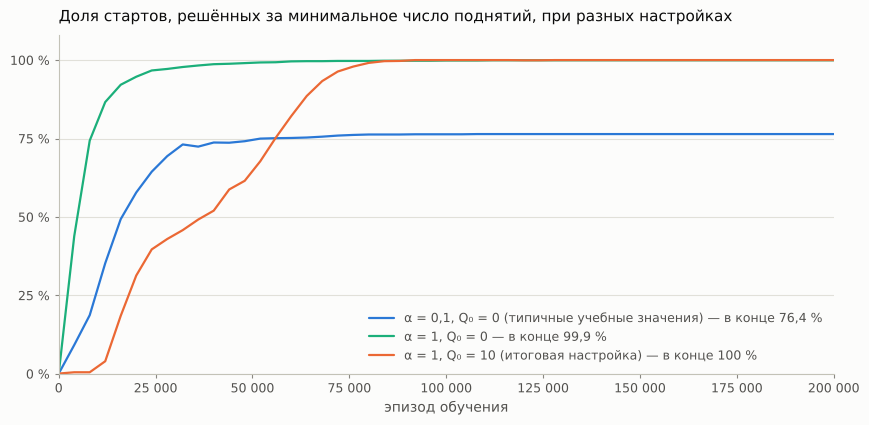

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.4), facecolor=SURFACE)
style_axes(ax)
for c in comparison:
    x = [ep for ep, _ in c["evals"]]
    y = np.array([m["optimal"] for _, m in c["evals"]]) * 100
    end = f"{y[-1]:.1f}".replace(".", ",").replace(",0", "")
    ax.plot(x, y, color=c["color"], linewidth=1.6, solid_capstyle="round",
            label=f"{c['label']} — в конце {end} %")
ax.set_title("Доля стартов, решённых за минимальное число поднятий, при разных настройках",
             loc="left", color=INK, fontsize=11, pad=10)
ax.set_ylim(0, 108)
ax.set_xlim(0, EPISODES)
ax.yaxis.set_major_locator(MultipleLocator(25))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.0f} %"))
ax.xaxis.set_major_formatter(FuncFormatter(thousands))
ax.set_xlabel("эпизод обучения", color=INK_2, fontsize=10)
ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK_2)
fig.savefig("images/compare.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.show()

**Что видно:**

- с **α = 0,1** оценки обновляются медленно: за 200 000 эпизодов агент так и не научился решать все расстановки оптимально;
- с **α = 1, Q₀ = 0** агент учится быстрее всех, но на одной расстановке застревает навсегда;
- с **оптимистичной инициализацией Q₀ = 10** начало медленнее (агент тратит время на то, чтобы перепробовать все действия), зато в итоге оптимальны все 100 % расстановок.

Разберём ошибку агента с α = 1, Q₀ = 0. Посмотрим его Q-значения в стартовом состоянии этой расстановки для действий из стакана, где компота больше всего:

In [15]:
stuck = comparison[1]
if not stuck["misses"]:
    print("С этой настройкой агент не ошибся ни разу.")
else:
    levels, _ = stuck["misses"][0]
    env_s = CompoteEnv()
    state = env_s.reset(levels)
    q = stuck["agent"].q(state)
    src = levels.index(max(levels))
    print(f"Расстановка {levels}, руки свободны. Действия из стакана {src + 1}:")
    for a in env_s.valid_actions():
        i, j = env_s.actions[a]
        if i == src:
            print(f"  стакан {i + 1} → стакан {j + 1}: Q = {q[a]:.2f}")
    print()
    show_solution(stuck["agent"], tuple(8 + d for d in levels))

Расстановка (0, 0, 0, -2, 2), руки свободны. Действия из стакана 5:
  стакан 5 → стакан 1: Q = 7.82
  стакан 5 → стакан 2: Q = 7.82
  стакан 5 → стакан 3: Q = 7.82
  стакан 5 → стакан 4: Q = 0.00

Было (│ — средний уровень):
  1 ████████│     8
  2 ████████│     8
  3 ████████│     8
  4 ██████  │     6
  5 ████████│██   10

Поднятие 1: стакан 5 → стакан 2 (+1), стакан 4 (+1)
Поднятие 2: стакан 2 → стакан 4 (+1)

Стало:
  1 ████████│     8
  2 ████████│     8
  3 ████████│     8
  4 ████████│     8
  5 ████████│     8

Поднятий: 2, теоретический минимум: 1  ✗ больше минимума


Чтобы выровнять стаканы за одно поднятие, нужно перелить из 5-го стакана в 4-й. Но в стартовом состоянии агент ни разу не попробовал это действие: его Q так и осталось равным 0, а у действий «лить из 5-го в 1-й, 2-й или 3-й» — около 7,8. Поэтому агент льёт сначала в стакан, который и так на уровне, а потом приходится поднимать ещё и его.

Стартовые состояния («руки свободны») встречаются только на первом шаге эпизода, поэтому такие пробелы там не успевают закрыться. С Q₀ = 10 неиспробованное действие кажется агенту лучше всех, и он его обязательно пробует.

## 8. Итог

| Требование задания | Результат |
|---|---|
| перелить компот так, чтобы везде было поровну | агент выравнивает все 1 450 возможных расстановок |
| поднимать стаканы минимальное число раз | во всех 1 450 случаях число поднятий равно теоретическому минимуму — числу стаканов выше среднего |
| вывести кривую обучения | раздел 4: награда растёт от −40 (случайные действия) до теоретического максимума 7,90 |

Главное в решении:

- в состояние входит стакан в руке — иначе нельзя отличить бесплатное переливание от нового поднятия;
- награда −1 за поднятие и +10 за успех делает «максимум награды» тем же самым, что «минимум поднятий»;
- α = 1 подходит, потому что среда детерминированная, а оптимистичная инициализация Q₀ = 10 заставляет агента перепробовать все действия и не застрять на первом найденном варианте.